In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

**1) LOADING THE DATA**

In [ ]:
df = pd.read_excel("data.xlsx")

**2) EDA**

In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
df.shape

(541909, 8)

In [ ]:
# Descriptive statistics
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalSales
count,406829.000000,406829,406829.000000,406829.000000,406829.000000
mean,12.061303,2011-07-10 16:30:57.879207424,3.460471,15287.690570,20.401854
min,-80995.000000,2010-12-01 08:26:00,0.000000,12346.000000,-168469.600000
25%,2.000000,2011-04-06 15:02:00,1.250000,13953.000000,4.200000
50%,5.000000,2011-07-31 11:48:00,1.950000,15152.000000,11.100000
75%,12.000000,2011-10-20 13:06:00,3.750000,16791.000000,19.500000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,168469.600000
std,248.693370,NaN,69.315162,1713.600303,427.591718


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [ ]:
# Convert 'CustomerID' to int64 and check if done
df['CustomerID'] = pd.to_numeric(df['CustomerID'], errors='coerce').astype('Int64')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  Int64         
 7   Country      541909 non-null  object        
dtypes: Int64(1), datetime64[ns](1), float64(1), int64(1), object(4)
memory usage: 33.6+ MB


In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [ ]:
# Checking nulls across all columns
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0
TotalSales,0


In [ ]:
# Deleting all nulls
df.dropna(subset=["CustomerID"], inplace=True)

In [ ]:
# Checking if all null entries have been deleted
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0
TotalSales,0


**3) FEATURE ENGINEERING (Feature Creation)**

In [ ]:
# Creating a new column "TotalSales"
df["TotalSales"] = df["Quantity"] * df["UnitPrice"]
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [ ]:
df.shape

(406829, 9)

In [ ]:
# Checking ALL duplicates (including first occurences)
all_duplicates = df[df.duplicated(keep=False)]
all_duplicates.shape

(10062, 9)

In [ ]:
# Checking the actual duplicates (excluding first occurences)
actual_duplicates = df[df.duplicated(keep='first')]
actual_duplicates.shape

(5225, 9)

In [ ]:
# Deleting actual duplicates
df = df.drop_duplicates(keep='first')
df.shape

(401604, 9)

In [ ]:
# Aggregate data at the customer level
customer_df = df.groupby("CustomerID").agg(
    TotalSales=("TotalSales", "sum"),
    TotalOrders=("InvoiceNo", "nunique"),
).reset_index()

# Display first few rows
customer_df.head()

,CustomerID,TotalSales,TotalOrders
0,12346.0,0.00,2
1,12347.0,4310.00,7
2,12348.0,1797.24,4
3,12349.0,1757.55,1
4,12350.0,334.40,1


In [ ]:
customer_df.shape

(4372, 3)

In [ ]:
# Deleting all entries with "zero" & "negative" Totalsales
customer_df = customer_df[customer_df['TotalSales'] > 0]
customer_df.shape

(4322, 3)

In [ ]:
customer_df.head()

,CustomerID,TotalSales,TotalOrders
1,12347.0,4310.00,7
2,12348.0,1797.24,4
3,12349.0,1757.55,1
4,12350.0,334.40,1
5,12352.0,1545.41,11


In [ ]:
# Descriptive statistics on the selected features
customer_df[["TotalSales", "TotalOrders"]].describe()

,TotalSales,TotalOrders
count,4.322000e+03,4322.000000
mean,1.918498e+03,5.115687
std,8.262490e+03,9.384459
min,1.776357e-15,1.000000
25%,3.005975e+02,1.000000
50%,6.533250e+02,3.000000
75%,1.624118e+03,6.000000
max,2.794890e+05,248.000000


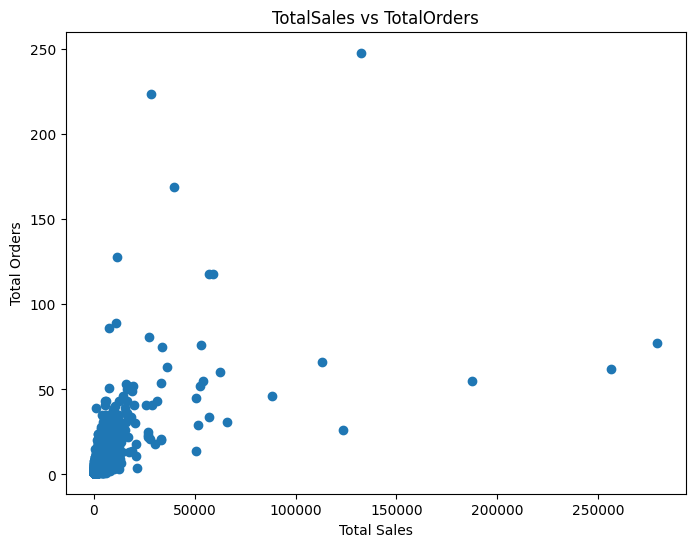

In [ ]:
# Visualizing the selected features: customer_df
plt.figure(figsize=(8, 6))
plt.scatter(customer_df["TotalSales"], customer_df["TotalOrders"])
plt.xlabel("Total Sales")
plt.ylabel("Total Orders")
plt.title("TotalSales vs TotalOrders")
plt.show()

**4) PREPROCESSING**

In [ ]:
# Standardize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer_df[["TotalSales", "TotalOrders"]])

# Convert the scaled NumPy array back to a Pandas DataFrame to use
X_scaled_df = pd.DataFrame(X_scaled, columns=["TotalSales", "TotalOrders"], index=customer_df.index)
X_scaled_df.head()

,TotalSales,TotalOrders
1,0.289474,0.200814
2,-0.014677,-0.118900
3,-0.019482,-0.438615
4,-0.191744,-0.438615
5,-0.045160,0.627100


**5) MODEL TRAINING**

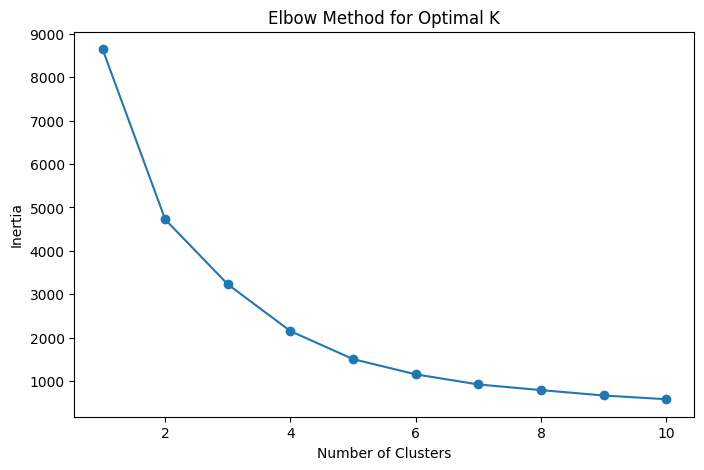

In [ ]:
# Determine the optimal number of clusters using the Elbow Method
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled_df)
    inertia.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8,5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.show()

In [ ]:
# Apply K-Means clustering with the optimal K (based on elbow method)
optimal_k = 4  # Adjust based on the elbow curve
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
customer_df["Cluster"] = kmeans.fit_predict(X_scaled_df)

# Display cluster counts
customer_df["Cluster"].value_counts()

,count
Cluster,
0,3915
3,382
2,22
1,3


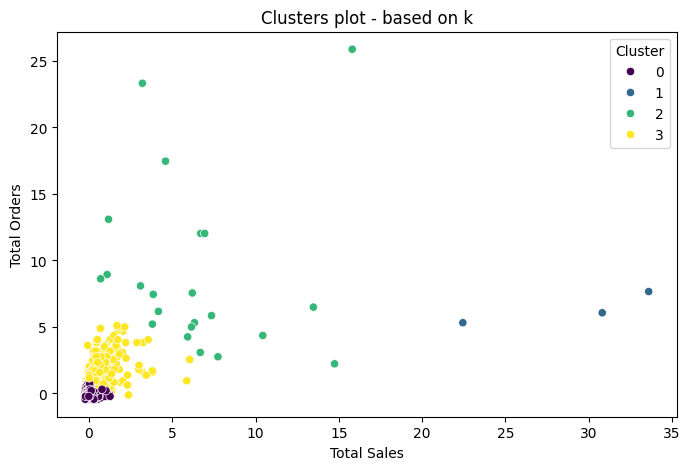

In [ ]:
# Scatter plot of scaled Total Sales vs. Total Orders colored by cluster
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_scaled_df["TotalSales"], y=X_scaled_df["TotalOrders"], hue=customer_df["Cluster"], palette="viridis")
plt.xlabel("Total Sales")
plt.ylabel("Total Orders")
plt.title("Clusters plot - based on k")
plt.show()

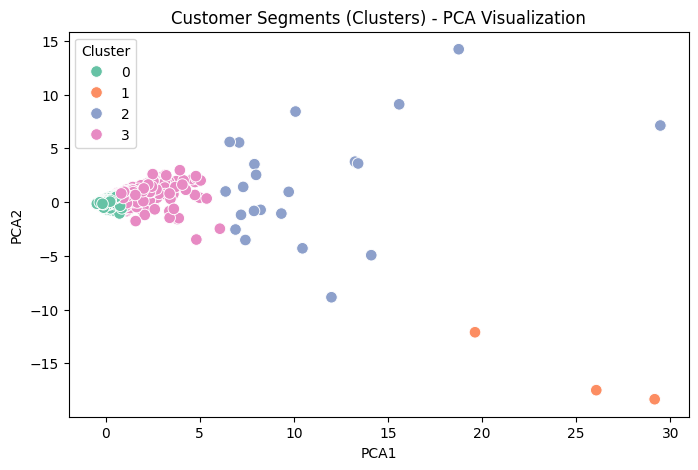

In [ ]:
# Using PCA at the prospect of visually improving cluster separation
pca = PCA(n_components=2)
pca_features = pca.fit_transform(X_scaled)
customer_df['PCA1'] = pca_features[:, 0]
customer_df['PCA2'] = pca_features[:, 1]

# Visualize
plt.figure(figsize=(8, 5))
sns.scatterplot(data=customer_df, x='PCA1', y='PCA2', hue='Cluster', palette='Set2', s=70)
plt.title("Customer Segments (Clusters) - PCA Visualization")
plt.show()

In [ ]:
# Appending the cluster number to each entry in the dataframe
customer_df["Cluster"] = kmeans.fit_predict(X_scaled)

# Display first few rows with clusters
customer_df.head()

,CustomerID,TotalSales,TotalOrders,Cluster,PCA1,PCA2
1,12347.0,4310.00,7,0,0.346686,-0.062692
2,12348.0,1797.24,4,0,-0.094454,-0.073697
3,12349.0,1757.55,1,0,-0.323923,-0.296372
4,12350.0,334.40,1,0,-0.445731,-0.174564
5,12352.0,1545.41,11,0,0.411494,0.475359


In [ ]:
# Counting the number of customers in each cluster
cluster_dfs = {}

# Iterate through unique cluster numbers
for cluster_num in customer_df["Cluster"].unique():
  # Create a dataframe for the current cluster
  cluster_dfs[cluster_num] = customer_df[customer_df["Cluster"] == cluster_num]
  # Print the count of customer IDs in the current cluster dataframe
  print(f"Cluster {cluster_num}: {len(cluster_dfs[cluster_num])} customers")

Cluster 0: 3915 customers
Cluster 3: 382 customers
Cluster 2: 22 customers
Cluster 1: 3 customers


In [ ]:
# Calculate and display the average TotalSales and TotalOrders per cluster
for cluster_num, cluster_df in cluster_dfs.items():
  avg_totalsales = cluster_df["TotalSales"].mean()
  avg_totalorders = cluster_df["TotalOrders"].mean()
  print(f"Cluster {cluster_num}:")
  print(f"  Average TotalSales: {avg_totalsales:.2f}")
  print(f"  Average TotalOrders: {avg_totalorders:.2f}")

Cluster 0:
  Average TotalSales: 944.33
  Average TotalOrders: 3.22
Cluster 3:
  Average TotalSales: 6992.27
  Average TotalOrders: 19.29
Cluster 2:
  Average TotalSales: 54563.86
  Average TotalOrders: 88.36
Cluster 1:
  Average TotalSales: 241083.23
  Average TotalOrders: 64.67


In [ ]:
# Calculate the min, avg and max TotalSales and TotalOrders per cluster
cluster_stats = {}

# Iterate through each cluster
for cluster_num in customer_df['Cluster'].unique():
    cluster_data = customer_df[customer_df['Cluster'] == cluster_num]
    cluster_stats[cluster_num] = {
        'min_totalsales': cluster_data['TotalSales'].min(),
        'avg_totalsales': cluster_data['TotalSales'].mean(),
        'max_totalsales': cluster_data['TotalSales'].max(),
        'min_totalorders': cluster_data['TotalOrders'].min(),
        'avg_totalorders': cluster_data['TotalOrders'].mean(),
        'max_totalorders': cluster_data['TotalOrders'].max()
    }

# Convert the dictionary to a DataFrame
cluster_stats_df = pd.DataFrame.from_dict(cluster_stats, orient='index')

# Display the DataFrame
cluster_stats_df

,min_totalsales,avg_totalsales,max_totalsales,min_totalorders,avg_totalorders,max_totalorders
0,1.776357e-15,944.328497,12393.70,1,3.219413,12
3,5.734500e+02,6992.272199,51823.72,4,19.287958,53
2,7.709690e+03,54563.856364,132458.73,26,88.363636,248
1,1.873222e+05,241083.226667,279489.02,55,64.666667,77


**6) MODEL EVALUATION**

In [ ]:
sil_score = silhouette_score(X_scaled, kmeans.labels_)
print(f"Silhouette Score: {sil_score}")
db_index = davies_bouldin_score(X_scaled, kmeans.labels_)
print(f"Davies-Bouldin Index: {db_index}")

Silhouette Score: 0.7676648475771769
Davies-Bouldin Index: 0.6476538588549042


**7) MODEL OPTIMIZATION (Hyperparameter tuning)**

In [ ]:
# Define the parameter grid
param_grid = {
    'n_clusters': [3, 4, 5, 6],
    'init': ['k-means++'],
    'n_init': [1, 20],
    'max_iter': [1, 100]
}

best_score = -1
best_dbi_score = float('inf')
best_params = None
best_model = None

# Manual grid search
for n_clusters in param_grid['n_clusters']:
    for init in param_grid['init']:
        for n_init in param_grid['n_init']:
            for max_iter in param_grid['max_iter']:
                kmeans = KMeans(
                    n_clusters=n_clusters,
                    init=init,
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=42
                )
                labels = kmeans.fit_predict(X_scaled)
                score = silhouette_score(X_scaled, labels)
                dbi = davies_bouldin_score(X_scaled, labels)

                if score > best_score:
                    best_score = score
                    best_params = {
                        'n_clusters': n_clusters,
                        'init': init,
                        'n_init': n_init,
                        'max_iter': max_iter
                    }
                    best_model = kmeans

                # Update best DBI score (minimization)
                if dbi < best_dbi_score:
                    best_dbi_score = dbi

# Output the best hyperparameters and score
print("Best hyperparameters:", best_params)
print("Best silhouette score:", best_score)
print("Best Davies-Bouldin Index:", best_dbi_score)

# Assign the best cluster labels to the DataFrame
customer_df['Cluster'] = best_model.labels_

Best hyperparameters: {'n_clusters': 3, 'init': 'k-means++', 'n_init': 20, 'max_iter': 1}
Best silhouette score: 0.8776449463785528
Best Davies-Bouldin Index: 0.611743172869309


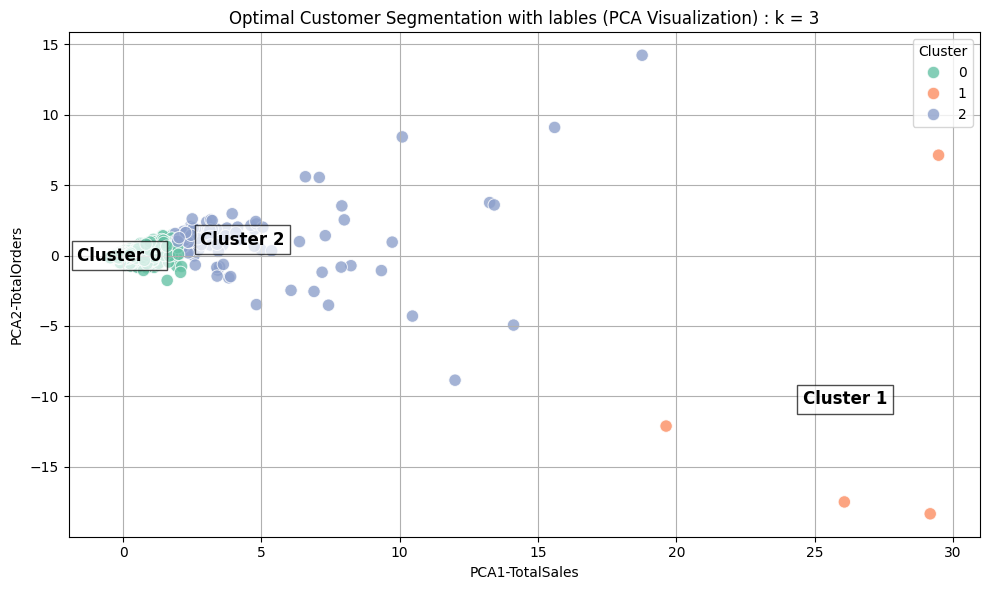

In [ ]:
# Labelling clusters

# Predict clusters using best model
customer_df["Cluster"] = best_model.predict(X_scaled)

# PCA
pca = PCA(n_components=2)
pca_features = pca.fit_transform(X_scaled)
customer_df["PCA1"] = pca_features[:, 0]
customer_df["PCA2"] = pca_features[:, 1]

# Scatter plotting using PCA
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=customer_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="Set2",
    s=80,
    alpha=0.8
)

# Adding cluster labels at centroids
for cluster_num in customer_df['Cluster'].unique():
    cluster_data = customer_df[customer_df['Cluster'] == cluster_num]
    centroid_x = cluster_data['PCA1'].mean()
    centroid_y = cluster_data['PCA2'].mean()
    plt.text(centroid_x, centroid_y, f'Cluster {cluster_num}',
             fontsize=12, weight='bold', ha='center', va='center',
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='black'))

plt.title(f"Optimal Customer Segmentation with lables (PCA Visualization) : k = {best_model.n_clusters}")
plt.xlabel("PCA1-TotalSales")
plt.ylabel("PCA2-TotalOrders")
plt.legend(title="Cluster")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Customer count per cluster after optimal segmentation

customer_df['Cluster'] = best_model.labels_

cluster_dfs = {}

for cluster_num in customer_df['Cluster'].unique():
    cluster_dfs[cluster_num] = customer_df[customer_df['Cluster'] == cluster_num]
    print(f"Cluster {cluster_num}: {len(cluster_dfs[cluster_num])} customers")

Cluster 0: 4209 customers
Cluster 2: 109 customers
Cluster 1: 4 customers


In [ ]:
# Summary: avg total sales and total orders per cluster

# Group by cluster and calculate mean of selected columns
cluster_summary = customer_df.groupby('Cluster')[['TotalSales', 'TotalOrders']].mean()

# Round for readability (optional)
cluster_summary = cluster_summary.round(6)

# Display the summary
print(cluster_summary)

            TotalSales  TotalOrders
Cluster                            
0          1232.705727     4.081492
1        213927.102500   110.500000
2         20620.016055    41.183486


In [ ]:
# Assign cluster labels to customer_df
customer_df['Cluster'] = best_model.labels_
customer_df[['CustomerID', 'TotalSales', 'TotalOrders', 'Cluster']].head(10)

,CustomerID,TotalSales,TotalOrders,Cluster
1,12347.0,4310.00,7,0
2,12348.0,1797.24,4,0
3,12349.0,1757.55,1,0
4,12350.0,334.40,1,0
5,12352.0,1545.41,11,0
6,12353.0,89.00,1,0
7,12354.0,1079.40,1,0
8,12355.0,459.40,1,0
9,12356.0,2811.43,3,0
10,12357.0,6207.67,1,0


In [ ]:
# Descriptive statistics per cluster after optimal segmentation

for cluster_num, df in cluster_dfs.items():
    print(f"\n--- Cluster {int(cluster_num)} Summary ---")

    # Drop irrelevant columns
    df_filtered = df.drop(columns=['CustomerID', 'PCA1', 'PCA2', 'Cluster'], errors='ignore')

    # Descriptive statistics
    summary = df_filtered.describe(include='all')

    # Format TotalOrders as whole numbers
    if 'TotalOrders' in summary.columns:
        summary['TotalOrders'] = summary['TotalOrders'].apply(
            lambda x: f"{int(round(x))}" if pd.notnull(x) else x
        )

    # Format TotalSales with 2 decimal places (no scientific notation)
    if 'TotalSales' in summary.columns:
        summary['TotalSales'] = summary['TotalSales'].apply(
            lambda x: f"{x:.2f}" if pd.notnull(x) else x
        )

    # Print the formatted summary
    print(summary.to_string())


--- Cluster 0 Summary ---
      TotalSales TotalOrders
count    4209.00        4209
mean     1232.71           4
std      1689.88           4
min         0.00           1
25%       294.24           1
50%       632.40           3
75%      1491.43           5
max     21535.90          27

--- Cluster 2 Summary ---
      TotalSales TotalOrders
count     109.00         109
mean    20620.02          41
std     21436.70          29
min      1296.44          14
25%      7709.69          27
50%     12279.82          31
75%     26763.34          43
max    123725.45         224

--- Cluster 1 Summary ---
      TotalSales TotalOrders
count       4.00           4
mean   213927.10         110
std     66958.95          92
min    132458.73          55
25%    173606.31          60
50%    221880.33          70
75%    262201.12         120
max    279489.02         248


**SUMMARY**
---------


**1) Clusters**
*   Cluster 0: Low Spenders
*   Cluster 1: Highest Spenders (Top)
*   Cluster 2: Moderate Spenders

**2) Best Model Parameters**:
{'n_clusters': 3, 'init': 'k-means++', 'n_init': 20, 'max_iter': 1}

**3) Metrics**
*   Best silhouette score: 0.8776449463785528
*   Best Davies-Bouldin Index: 0.611743172869309






